# Imports

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [14]:
peak_data = np.load(r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\PWR_INP_1_3.txt_temperature_arrays.npz")

# Extract individual arrays
z_coordinates = peak_data["z_coordinates"]
fuel_average = peak_data["fuel_average"]
fuel_centreline = peak_data["fuel_centreline"]
clad_inner_surface = peak_data["clad_inner_surface"]
clad_outer_surface = peak_data["clad_outer_surface"]
coolant_temperature = peak_data["coolant_temperature"]

print("COBRA data loaded successfully!")
print("Number of axial positions:", len(z_coordinates))

COBRA data loaded successfully!
Number of axial positions: 18


In [15]:
for lists in [z_coordinates, fuel_centreline, fuel_average, clad_inner_surface, clad_outer_surface]:
    print(len(lists))
plt.rcParams.update({
    "font.size": 14,  # default text size
    "axes.titlesize": 16,  # title size
    "axes.labelsize": 15,  # axis labels
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

plt.rcParams.update({
    "font.family": "Times New Roman",  # Use Times New Roman for all text
    "mathtext.fontset": "custom",  # Use custom font for math
    "mathtext.rm": "Times New Roman",  # Roman font in math
    "mathtext.it": "Times New Roman:italic",  # Italic font in math
    "mathtext.bf": "Times New Roman:bold",  # Bold font in math
    "text.usetex": False
})


# Fitting
def sinusoidal_model(x, intercept, scale_factor, coefficient):
    return intercept + scale_factor * np.sin(x * coefficient)


def cosinusoidal_model(x, intercept, scale_factor, coefficient):
    return intercept + scale_factor * np.cos(x * coefficient)

18
18
18
18
18


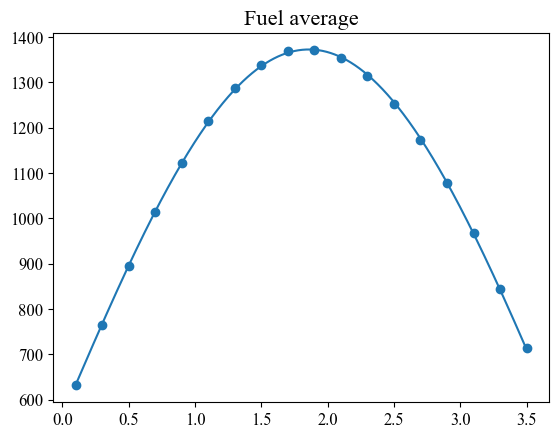

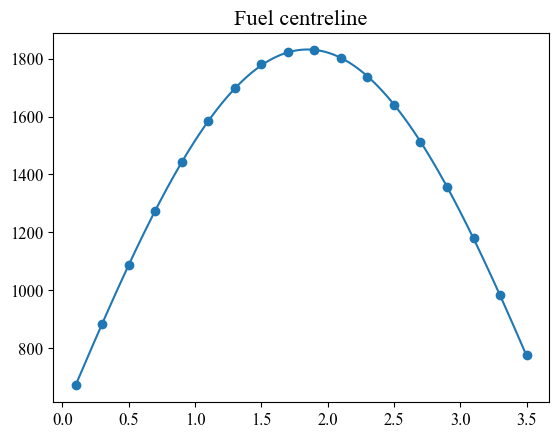

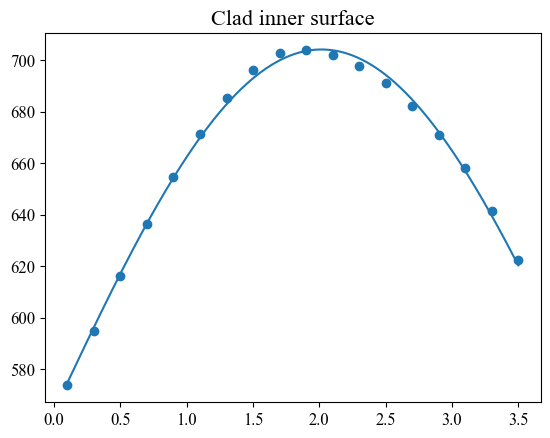

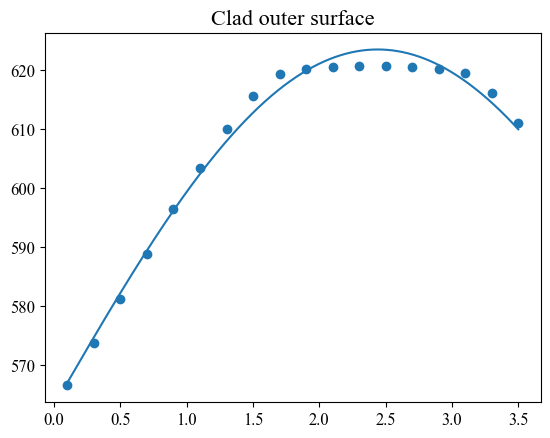

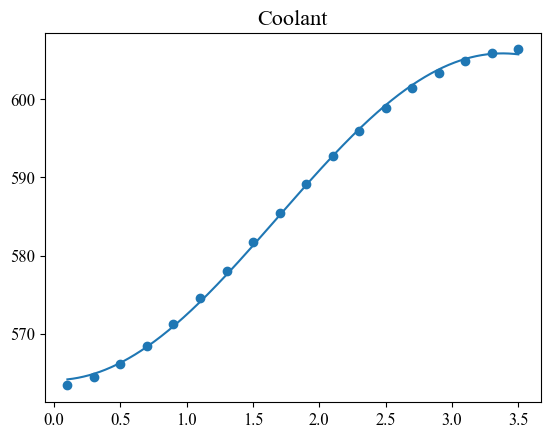

In [16]:
pops = []
covs = []
residuals = []

xrange = np.linspace(z_coordinates[0], z_coordinates[-1], 1000)

datasets = [fuel_average, fuel_centreline, clad_inner_surface, clad_outer_surface]

labels = [
    "Fuel average",
    "Fuel centreline",
    "Clad inner surface",
    "Clad outer surface"
]

for dataset, label in zip(datasets, labels):
    p0 = [0, np.max(dataset), z_coordinates[-1] / np.pi]

    pop, cov = curve_fit(sinusoidal_model,
                         z_coordinates,
                         dataset,
                         p0=p0,
                         maxfev=50000)

    residual = dataset - sinusoidal_model(z_coordinates, *pop)

    plt.figure(1)
    plt.scatter(z_coordinates, dataset)
    plt.title(label)

    plt.plot(xrange, sinusoidal_model(xrange, *pop))

    plt.show()

    pops.append(pop)
    covs.append(cov)
    residuals.append(residual)

p0_coolant = [0, np.max(coolant_temperature), z_coordinates[-1] / np.pi]

pop_coolant, cov_coolant = curve_fit(cosinusoidal_model,
                                     z_coordinates,
                                     coolant_temperature,
                                     p0=p0_coolant,
                                     maxfev=50000)

residual_coolant = coolant_temperature - cosinusoidal_model(z_coordinates, *pop_coolant)

plt.figure(1)
plt.scatter(z_coordinates, coolant_temperature)
plt.title("Coolant")

plt.plot(xrange, cosinusoidal_model(xrange, *pop_coolant))

plt.show()

pops.append(pop_coolant)
covs.append(cov_coolant)
residuals.append(residual_coolant)

datasets.append(coolant_temperature)
labels.append("Coolant")

# Plot 2: Temperature Distributions for peak power

In [17]:
color_list = ["#D55E00", "#0072B2", "#009E73", "#E69F00", "#CC79A7"]
marker_list = ["o", "D", "s", "h", "v"]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements_1 = []

for color, marker, label in zip(color_list[0:2], marker_list[0:2], labels[0:2]):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_1.append(((line, marker_handle), label))


legend_elements_2 = []

for color, marker, label in zip(color_list[2:], marker_list[2:], labels[2:]):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_2.append(((line, marker_handle), label))

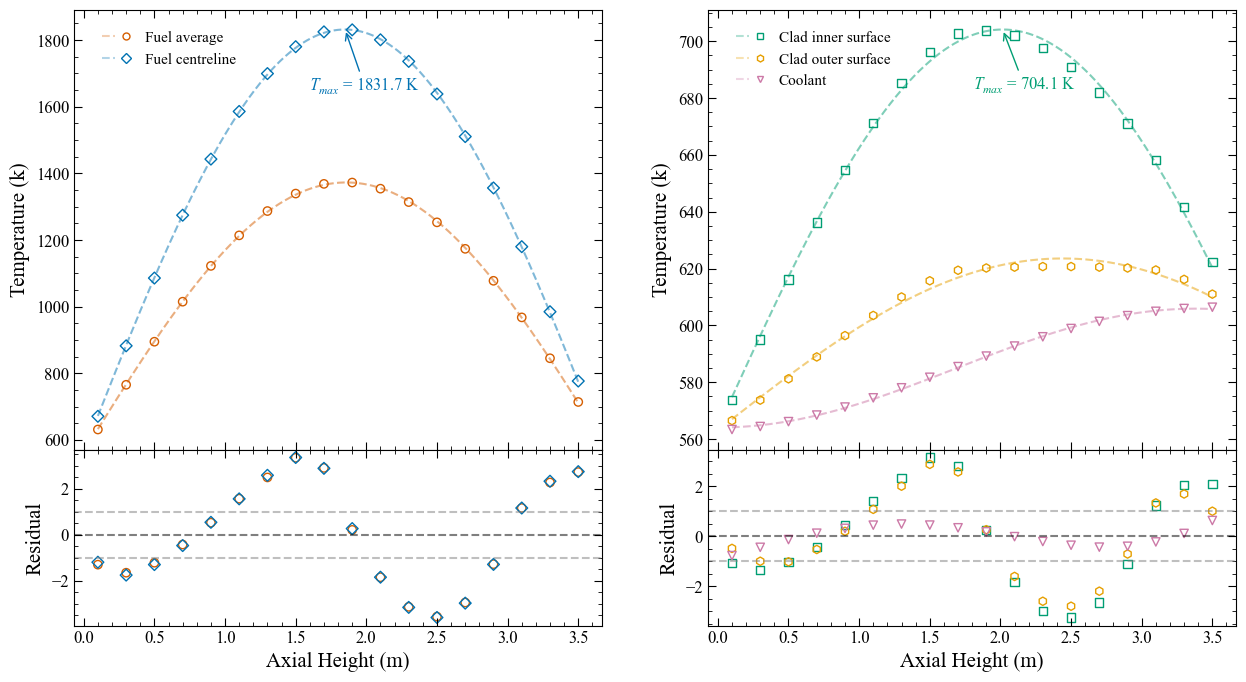

1831.6767253210185
704.1272885341896


In [18]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[5, 2],
    hspace=0
)

ax_main_left = fig.add_subplot(gs[0,0])
ax_res_left = fig.add_subplot(gs[1,0])

ax_main_right = fig.add_subplot(gs[0,1])
ax_res_right = fig.add_subplot(gs[1,1])
################
# Main Plot Left
################

for ydata, pop, colour, marker in zip(
        [fuel_average, fuel_centreline], pops[:-3], color_list[:-3],
        marker_list[:-3]):
    ax_main_left.scatter(z_coordinates, ydata,
                    marker=marker, color=colour, facecolor="none")

    ax_main_left.plot(xrange, sinusoidal_model(xrange, *pop),
                 color=colour, marker="none", linestyle="--", alpha=0.5)

ax_main_left.legend(
    handles=[item[0] for item in legend_elements_1],
    labels=[item[1] for item in legend_elements_1],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

ax_main_left.annotate(
    rf"$T_{{max}}$ = {np.max(sinusoidal_model(xrange, *pops[1])):.1f} K",
    xy=(xrange[np.argmax(sinusoidal_model(xrange, *pops[1]))], np.max(sinusoidal_model(xrange, *pops[1]))),
    xytext=(z_coordinates[np.argmax(fuel_centreline)]*0.84, np.max(sinusoidal_model(xrange, *pops[1]))*0.9),
    arrowprops=dict(arrowstyle="->", color= "#0072B2", lw=1),
    color="#0072B2",
    fontsize=12
)

#################
# Main Plot Right
#################

for ydata, pop, colour, marker in zip(
        [clad_inner_surface, clad_outer_surface], [pops[2],pops[3]], [color_list[2],color_list[3]],
        [marker_list[2],marker_list[3]]):
    ax_main_right.scatter(z_coordinates, ydata,
                    marker=marker, color=colour, facecolor="none")

    ax_main_right.plot(xrange, sinusoidal_model(xrange, *pop),
                 color=colour, marker="none", linestyle="--", alpha=0.5)

ax_main_right.scatter(z_coordinates, coolant_temperature,
                marker=marker_list[-1], color=color_list[-1], facecolor="none")

ax_main_right.plot(xrange, cosinusoidal_model(xrange, *pop_coolant),
             color=color_list[-1], marker="none", linestyle="--", alpha=0.5)

ax_main_right.legend(
    handles=[item[0] for item in legend_elements_2],
    labels=[item[1] for item in legend_elements_2],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

ax_main_right.annotate(
    rf"$T_{{max}}$ = {np.max(sinusoidal_model(xrange, *pops[2])):.1f} K",
    xy=(xrange[np.argmax(sinusoidal_model(xrange, *pops[2]))], np.max(sinusoidal_model(xrange, *pops[2]))),
    xytext=(z_coordinates[np.argmax(fuel_centreline)]*0.95, np.max(sinusoidal_model(xrange, *pops[2]))*0.97),
    arrowprops=dict(arrowstyle="->", color= "#009E73", lw=1),
    color="#009E73",
    fontsize=12
)

####################
# Residual Plot Left
####################


for residual, colour, marker in zip(
        residuals[0:2], color_list[0:2], marker_list[0:2]):
    ax_res_left.scatter(z_coordinates, residual,
                   marker=marker, color=colour, facecolor="none")

ax_res_left.axhline(0, linestyle="--", color="black", alpha=0.5)
ax_res_left.axhline(1, linestyle="--", color="grey", alpha=0.5)
ax_res_left.axhline(-1, linestyle="--", color="grey", alpha=0.5)

ax_res_left.set_ylabel("Residual")
ax_res_right.set_ylabel("Residual")

#####################
# Residual Plot Right
#####################


for residual, colour, marker in zip(
        residuals[2:], color_list[2:], marker_list[2:]):
    ax_res_right.scatter(z_coordinates, residual,
                   marker=marker, color=colour, facecolor="none")

ax_res_right.axhline(0, linestyle="--", color="black", alpha=0.5)
ax_res_right.axhline(1, linestyle="--", color="grey", alpha=0.5)
ax_res_right.axhline(-1, linestyle="--", color="grey", alpha=0.5)

#####################
# Formatting and Save
#####################

ax_res_left.set_xlabel("Axial Height (m)")
ax_main_left.set_ylabel("Temperature (k)")

ax_res_right.set_xlabel("Axial Height (m)")
ax_main_right.set_ylabel("Temperature (k)")

for ax in [ax_main_left, ax_main_right, ax_res_left, ax_res_right]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_Peak_Temperature_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
############################
# Obtaining Peak Temperature
############################

resolved_x_range = np.linspace(0, 3.66, 100000)
T_centreline = sinusoidal_model(resolved_x_range, *pops[1])
T_centreline_peak = np.max(T_centreline)

T_inner_surf = sinusoidal_model(resolved_x_range, *pops[2])
T_inner_surf_peak = np.max(T_inner_surf)

print(T_centreline_peak)
print(T_inner_surf_peak)

In [19]:
np.savez("data_1_2.npz",
         centreline_fit_peak = T_centreline,
         centreline_peak = fuel_centreline,
         z_coordinates_peak = z_coordinates,
         inner_surf_fit_peak = T_inner_surf,
         inner_surf_peak = clad_inner_surface,
         residual_centreline_peak = residuals[1],
         residual_surf_peak = residuals[2])